# Deployment dan Monitoring Machine Learning di Jupyter Notebook

Notebook ini menjalankan model **Gradient Boosting Regressor** untuk memprediksi *Performance Index* dan mencatat setiap prediksi ke `monitoring_log.csv`. Letakkan notebook ini di folder yang sama dengan `gbr_model.joblib` dan `scaler.joblib`.

## 1. Import library dan memuat model
Jalankan sel ini terlebih dahulu. Jika file model tidak ditemukan, pastikan notebook berada di folder proyek yang benar.

In [2]:
from pathlib import Path
from datetime import datetime
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FOLDER = Path.cwd()
MODEL_PATH = FOLDER / "gbr_model.joblib"
SCALER_PATH = FOLDER / "scaler.joblib"
LOG_PATH = FOLDER / "monitoring_log.csv"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model tidak ditemukan: {MODEL_PATH}. Pindahkan notebook ke folder yang berisi gbr_model.joblib.")
if not SCALER_PATH.exists():
    raise FileNotFoundError(f"Scaler tidak ditemukan: {SCALER_PATH}. Pindahkan notebook ke folder yang berisi scaler.joblib.")

model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)
FEATURES = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample Question Papers Practiced",
]
print("Model dan scaler berhasil dimuat.")
print("Folder kerja:", FOLDER)

Model dan scaler berhasil dimuat.
Folder kerja: C:\Users\Zahra Sansabila\Downloads\PRAKTIKUM_LAB_ML_DEPLOYMENT_MONITORING_JUPYTER\PRAKTIKUM_LAB_ML


## 2. Fungsi pencatatan monitoring
Fungsi ini menyimpan input, hasil prediksi, status, dan lama pemrosesan ke CSV.

In [3]:
def simpan_log(record):
    """Menambahkan satu catatan aktivitas prediksi ke file CSV."""
    baris = pd.DataFrame([record])
    if LOG_PATH.exists():
        baris.to_csv(LOG_PATH, mode="a", header=False, index=False)
    else:
        baris.to_csv(LOG_PATH, index=False)

print("Fungsi monitoring siap digunakan.")

Fungsi monitoring siap digunakan.


## 3. Deployment: memasukkan data dan melakukan prediksi
Jalankan sel berikut, lalu masukkan nilai ketika diminta. Encoding aktivitas ekstrakurikuler mengikuti format model: `No = 0` dan `Yes = 1`.

In [4]:
def prediksi_performance(hours, previous_scores, extracurricular, sleep_hours, sample_papers):
    mulai = time.perf_counter()
    status = "success"
    pesan_error = ""
    hasil = None

    try:
        if extracurricular not in ["No", "Yes"]:
            raise ValueError("Extracurricular Activities harus diisi No atau Yes.")
        data_baru = pd.DataFrame([{
            "Hours Studied": float(hours),
            "Previous Scores": float(previous_scores),
            "Extracurricular Activities": 1 if extracurricular == "Yes" else 0,
            "Sleep Hours": float(sleep_hours),
            "Sample Question Papers Practiced": float(sample_papers),
        }], columns=FEATURES)

        data_scaled = scaler.transform(data_baru)
        hasil = float(model.predict(data_scaled)[0])
        print(f"Hasil prediksi Performance Index: {hasil:.2f}")
    except Exception as e:
        status = "error"
        pesan_error = str(e)
        print("Prediksi gagal:", pesan_error)

    durasi_ms = round((time.perf_counter() - mulai) * 1000, 3)
    simpan_log({
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "Hours Studied": hours,
        "Previous Scores": previous_scores,
        "Extracurricular Activities": extracurricular,
        "Sleep Hours": sleep_hours,
        "Sample Question Papers Practiced": sample_papers,
        "prediction": hasil,
        "latency_ms": durasi_ms,
        "status": status,
        "error_message": pesan_error,
    })
    print(f"Status: {status} | Waktu pemrosesan: {durasi_ms:.2f} ms")
    print(f"Log tersimpan di: {LOG_PATH}")
    return hasil

# Ubah nilai di bawah sesuai data yang ingin diuji
hasil_prediksi = prediksi_performance(
    hours=5,
    previous_scores=70,
    extracurricular="Yes",
    sleep_hours=7,
    sample_papers=3
)

Hasil prediksi Performance Index: 55.88
Status: success | Waktu pemrosesan: 59.59 ms
Log tersimpan di: C:\Users\Zahra Sansabila\Downloads\PRAKTIKUM_LAB_ML_DEPLOYMENT_MONITORING_JUPYTER\PRAKTIKUM_LAB_ML\monitoring_log.csv


C:\Users\Zahra Sansabila\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


## 4. Monitoring: ringkasan aktivitas prediksi
Jalankan setelah melakukan satu atau beberapa prediksi. Sel ini menampilkan jumlah prediksi, prediksi berhasil/gagal, dan rata-rata waktu pemrosesan.

In [5]:
if LOG_PATH.exists():
    logs = pd.read_csv(LOG_PATH)
    total = len(logs)
    berhasil = int((logs["status"] == "success").sum()) if "status" in logs else 0
    gagal = int((logs["status"] == "error").sum()) if "status" in logs else 0
    rata_latency = float(logs["latency_ms"].mean()) if total and "latency_ms" in logs else 0.0

    print("===== RINGKASAN MONITORING =====")
    print("Total prediksi       :", total)
    print("Prediksi berhasil    :", berhasil)
    print("Prediksi gagal       :", gagal)
    print(f"Rata-rata latensi    : {rata_latency:.2f} ms")
    display(logs.tail(20).iloc[::-1])
else:
    print("Belum ada log. Jalankan sel Deployment terlebih dahulu.")

===== RINGKASAN MONITORING =====
Total prediksi       : 1
Prediksi berhasil    : 1
Prediksi gagal       : 0
Rata-rata latensi    : 59.59 ms


,timestamp,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,prediction,latency_ms,status,error_message
0,2026-10-18T22:09:37,5,70,Yes,7,3,55.876569,59.59,success,NaN


## 5. Visualisasi hasil prediksi dan waktu pemrosesan

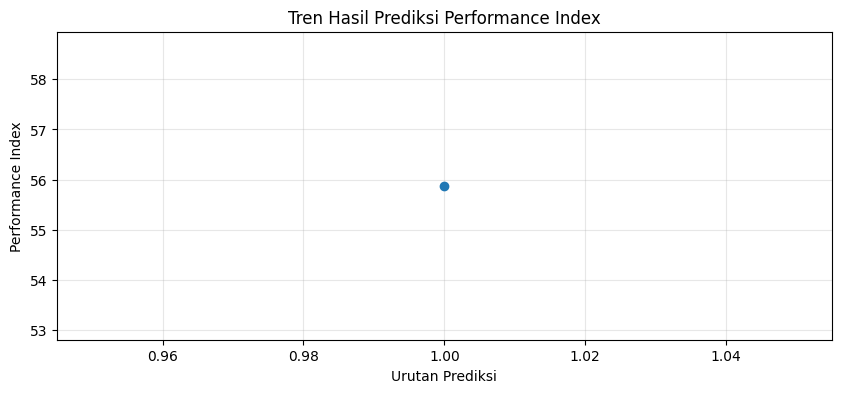

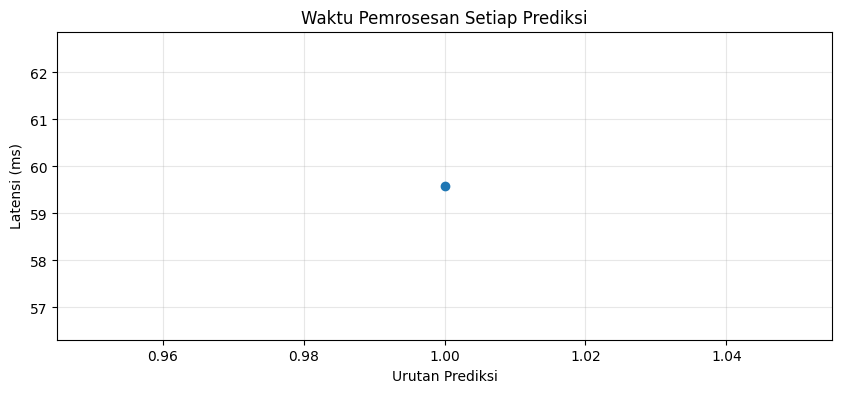

In [6]:
if LOG_PATH.exists():
    logs = pd.read_csv(LOG_PATH)
    if "prediction" in logs and logs["prediction"].notna().any():
        plt.figure(figsize=(10, 4))
        plt.plot(range(1, len(logs) + 1), logs["prediction"], marker="o")
        plt.title("Tren Hasil Prediksi Performance Index")
        plt.xlabel("Urutan Prediksi")
        plt.ylabel("Performance Index")
        plt.grid(True, alpha=0.3)
        plt.show()

    if "latency_ms" in logs and not logs.empty:
        plt.figure(figsize=(10, 4))
        plt.plot(range(1, len(logs) + 1), logs["latency_ms"], marker="o")
        plt.title("Waktu Pemrosesan Setiap Prediksi")
        plt.xlabel("Urutan Prediksi")
        plt.ylabel("Latensi (ms)")
        plt.grid(True, alpha=0.3)
        plt.show()
else:
    print("Belum ada log monitoring untuk divisualisasikan.")

## 6. Mengunduh/menyimpan log monitoring
File `monitoring_log.csv` berada di folder proyek. Sel berikut menampilkan lokasi file dan dapat digunakan untuk memastikan log sudah dibuat.

In [7]:
if LOG_PATH.exists():
    print("File log tersedia:", LOG_PATH.resolve())
    print("Ukuran data log:", len(pd.read_csv(LOG_PATH)), "baris")
else:
    print("File log belum dibuat. Jalankan prediksi terlebih dahulu.")

File log tersedia: C:\Users\Zahra Sansabila\Downloads\PRAKTIKUM_LAB_ML_DEPLOYMENT_MONITORING_JUPYTER\PRAKTIKUM_LAB_ML\monitoring_log.csv
Ukuran data log: 1 baris


## Kesimpulan
- **Deployment** dilakukan dengan memuat model dan scaler yang telah disimpan, lalu memprediksi data baru menggunakan fungsi `prediksi_performance()`.
- **Monitoring** mencatat setiap percobaan prediksi, status berhasil/gagal, dan waktu pemrosesan.
- Grafik membantu melihat tren hasil prediksi dan latensi. Monitoring ini belum menghitung akurasi prediksi pada data baru karena diperlukan nilai aktual sebagai pembanding.